# Pair 3: Upscaling small supplier photos, AuraSR v2 (System A) vs HYPIR (System B)

About 1,500 supplier photos a month are too small for our zoom view, and a reshoot costs about AUD 36 per photo. Can a
model enlarge them 4x without inventing details the product doesn't have?

- System A, AuraSR v2 (fal, 2024): GigaGAN-style GAN upscaler trained from scratch, one forward pass on 64 px tiles.
- System B, HYPIR (Lin et al., SIGGRAPH 2025): a GAN whose generator starts from Stable Diffusion 2.1's UNet and is
  fine-tuned adversarially with LoRA, so it uses a diffusion prior but still runs in one forward pass (weeks 9 and 10).
- Baseline: bicubic interpolation.

8 real product photos are shrunk 4x in two ways (clean, and a "supplier" version with blur and JPEG), giving 16 inputs,
each enlarged with seeds 0, 1 and 2. I measure fidelity to the real photo (PSNR, SSIM, LPIPS), realism (MUSIQ), colour
shift on the product (CIEDE2000) and printed text kept or invented (OCR), speed and a simple cost comparison.

To run on Kaggle: GPU T4 x2, Internet on, then Save & Run All (about 30 min).

In [ ]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], capture_output=True)   # clashes with diffusers 0.41
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "aura-sr==0.0.4", "diffusers==0.41.0", "transformers==5.20.1",
                "accelerate==1.15.0", "peft==0.21.2", "pyiqa==0.1.16", "einops", "easyocr==1.7.2"], check=True, capture_output=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'aura-sr==0.0.4', 'diffusers==0.41.0', 'transformers==5.20.1', 'accelerate==1.15.0', 'peft==0.21.2', 'pyiqa==0.1.16', 'einops', 'easyocr==1.7.2'], returncode=0, stdout=b'', stderr=b"ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.\ngradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.\n")

In [ ]:
import csv, gzip, io, json, os, random, re, shutil, time, urllib.request
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageFilter
from scipy import ndimage
from scipy.stats import wilcoxon

OUT = Path("/kaggle/working/pair3")
OUT.mkdir(parents=True, exist_ok=True)
A, B, BASE = "AuraSR v2", "HYPIR", "Bicubic"
SEEDS = [0, 1, 2]
SCALE = 4
DAMAGE = {"clean": (0.0, None), "supplier": (0.8, 60)}     # (blur radius, JPEG quality) used to make the small inputs
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print(torch.cuda.get_device_name(0))

Tesla T4


## Data
Real catalogue photos from Amazon Berkeley Objects (Collins et al., 2022; CC BY 4.0, "Amazon Berkeley Objects,
Amazon.com"), picked at random (seed 0) across product types, clean shots on white only. Because I have the real
photo, every enlargement can be compared with the truth, which is why I shrink good photos instead of using photos
that are small to begin with.

In [ ]:
ABO = "https://amazon-berkeley-objects.s3.amazonaws.com"
CACHE = Path("/tmp/abo")


def download(url, dest):
    dest = Path(dest)
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=120) as r:
            dest.write_bytes(r.read())
    return dest


def product_mask(img):
    # product = everything that isn't the white background touching the border
    labels, _ = ndimage.label(np.asarray(img.convert("RGB")).min(axis=2) >= 240)
    border = np.unique(np.r_[labels[0], labels[-1], labels[:, 0], labels[:, -1]])
    return ndimage.binary_fill_holes(ndimage.binary_opening(~np.isin(labels, border[border > 0]), iterations=2))


listings = []
for shard in "0123":
    with gzip.open(download(f"{ABO}/listings/metadata/listings_{shard}.json.gz", CACHE / f"l{shard}.json.gz"), "rt") as f:
        for line in f:
            d = json.loads(line)
            name = next((x["value"] for x in d.get("item_name", []) if x.get("language_tag", "").startswith("en")), None)
            if name and d.get("main_image_id"):
                ptype = d["product_type"][0]["value"] if d.get("product_type") else "product"
                listings.append((d["item_id"], name, ptype, d["main_image_id"]))
with gzip.open(download(f"{ABO}/images/metadata/images.csv.gz", CACHE / "images.csv.gz"), "rt") as f:
    image_info = {r["image_id"]: r for r in csv.DictReader(f)}

by_type = {}
for item in listings:
    info = image_info.get(item[3])
    if info and min(int(info["width"]), int(info["height"])) >= 1024:
        by_type.setdefault(item[2], []).append((*item, info["path"]))
types = sorted(by_type)
random.Random(0).shuffle(types)

products = []
for t in types:
    item_id, name, ptype, _, path = random.Random(0).choice(by_type[t])
    url = f"{ABO}/images/original/{path}"
    img = Image.open(download(url, CACHE / "photos" / Path(path).name)).convert("RGB")
    m = product_mask(img.resize((256, round(256 * img.height / img.width))))
    if not (0.05 < m.mean() < 0.85 and np.r_[m[0], m[-1], m[:, 0], m[:, -1]].mean() < 0.05):
        continue
    img.thumbnail((1024, 1024))
    img = img.crop((0, 0, img.width - img.width % 16, img.height - img.height % 16))   # so big and small line up exactly
    img.save(CACHE / f"{item_id}.png")
    words = [w.lower() for w in re.findall(r"[A-Za-z]{3,}", name.split(",")[0]) if w.lower() not in ("amazon", "basics", "the", "and", "with", "for")]
    products.append({"item_id": item_id, "product": " ".join(words[-2:]) or ptype.lower(), "type": ptype,
                     "photo": str(CACHE / f"{item_id}.png"), "source_url": url, "licence": "CC BY 4.0, Amazon Berkeley Objects"})
    if len(products) == 8:
        break
products = pd.DataFrame(products)
products.to_csv(OUT / "products.csv", index=False)

jobs = []
(CACHE / "small").mkdir(parents=True, exist_ok=True)
for p in products.itertuples():
    hr = Image.open(p.photo)
    for kind, (blur, jpeg) in DAMAGE.items():
        lr = (hr.filter(ImageFilter.GaussianBlur(blur)) if blur else hr).resize((hr.width // SCALE, hr.height // SCALE), Image.BICUBIC)
        if jpeg:
            buf = io.BytesIO()
            lr.save(buf, "JPEG", quality=jpeg)
            lr = Image.open(buf).convert("RGB")
        lr.save(CACHE / "small" / f"{p.item_id}_{kind}.png")
        jobs.append({"job": f"{p.item_id}_{kind}", "item_id": p.item_id, "damage": kind, "hr": p.photo,
                     "lr": str(CACHE / "small" / f"{p.item_id}_{kind}.png"),
                     "prompt": f"a professional product photo of a {p.product} on a white background, high quality, sharp details"})
jobs = pd.DataFrame(jobs)
print(len(jobs), "small inputs from", len(products), "products")

16 small inputs from 8 products


## Running the systems
AuraSR runs as on its model card. HYPIR uses the authors' code (fixed commit) and test settings, with Stable Diffusion
2.1 base from a pinned copy (the original left the Hugging Face Hub in November 2025). The T4 has no bfloat16 and HYPIR
gave black images in float16, so it runs in float32 here. Every input is enlarged with seeds 0, 1 and 2; bicubic needs
no seed. The loading logs go to `model_log.txt`.

In [ ]:
%%capture model_output
if not Path("/tmp/HYPIR").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/XPixelGroup/HYPIR.git", "/tmp/HYPIR"], check=True)
    subprocess.run(["git", "-C", "/tmp/HYPIR", "checkout", "-q", "b61d107c6cef38f01a93c7833558869731cfa8c1"], check=True)
sys.path.insert(0, "/tmp/HYPIR")
from aura_sr import AuraSR
from huggingface_hub import hf_hub_download, snapshot_download
from HYPIR.enhancer.sd2 import SD2Enhancer
from torchvision.transforms.functional import to_tensor


def run(system, upscale, folder, seeds=SEEDS):
    rows = []
    for seed in seeds:
        (OUT / folder / f"seed{seed}").mkdir(parents=True, exist_ok=True)
        for j in jobs.itertuples():
            random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
            lr = Image.open(j.lr).convert("RGB")
            torch.cuda.synchronize(); t0 = time.time()
            sr = upscale(lr, j.prompt)
            torch.cuda.synchronize()
            sr = sr.resize((lr.width * SCALE, lr.height * SCALE), Image.BICUBIC) if sr.size != (lr.width * SCALE, lr.height * SCALE) else sr
            sr.save(OUT / folder / f"seed{seed}" / f"{j.job}.png")
            rows.append({"system": system, "seed": seed, "job": j.job, "seconds": time.time() - t0,
                         "output": str(OUT / folder / f"seed{seed}" / f"{j.job}.png")})
    return rows


aura = AuraSR.from_pretrained("fal/AuraSR-v2")
runs = run(A, lambda lr, prompt: aura.upscale_4x_overlapped(lr, max_batch_size=16), "aurasr")
del aura; torch.cuda.empty_cache()

base = snapshot_download("Manojb/stable-diffusion-2-1-base", revision="0094d483a120f3f33dafbd187ea4aa60d10de75c",
                         allow_patterns=["model_index.json", "scheduler/*", "tokenizer/*", "text_encoder/config.json",
                                         "text_encoder/model.safetensors", "unet/config.json", "unet/diffusion_pytorch_model.safetensors",
                                         "vae/config.json", "vae/diffusion_pytorch_model.safetensors"])
hypir = SD2Enhancer(base_model_path=base, weight_path=hf_hub_download("lxq007/HYPIR", "HYPIR_sd2.pth"),
                    lora_modules=["to_k", "to_q", "to_v", "to_out.0", "conv", "conv1", "conv2", "conv_shortcut", "conv_out",
                                  "proj_in", "proj_out", "ff.net.2", "ff.net.0.proj"],
                    lora_rank=256, model_t=200, coeff_t=200, device="cuda")    # the authors' test settings
hypir.weight_dtype = torch.float32
hypir.init_models()
runs += run(B, lambda lr, prompt: hypir.enhance(lq=to_tensor(lr)[None], prompt=prompt, scale_by="factor", upscale=SCALE,
                                                 patch_size=512, stride=256, return_type="pil")[0], "hypir")
del hypir; torch.cuda.empty_cache()

runs += run(BASE, lambda lr, prompt: lr.resize((lr.width * SCALE, lr.height * SCALE), Image.BICUBIC), "bicubic", seeds=[0])

In [ ]:
(OUT / "model_log.txt").write_text(model_output.stdout + model_output.stderr)
runs = pd.DataFrame(runs).merge(jobs, on="job")
assert all(np.asarray(Image.open(p)).max() > 0 for p in runs.output), "HYPIR produced a black image"
display(runs.groupby(["system", "seed"]).seconds.median().unstack().round(2))

seed,0,1,2
system,,,
AuraSR v2,4.47,4.64,4.81
Bicubic,0.15,NaN,NaN
HYPIR,11.47,12.12,12.19


## Metrics
- psnr_y and ssim_y on the luma channel (4 px border ignored), and lpips (lower is better): fidelity to the real photo.
- musiq: no-reference realism score. It also rewards invented texture, so it is read next to fidelity.
- delta_e: mean CIEDE2000 colour difference on the product pixels; about 3 or more is visible (Sharma et al., 2005).
- OCR on the real photo and on the enlargement: word_recall is the share of the real words that are still read,
  invented_words the number of words read on the enlargement that are not on the real photo.

PSNR alone would favour blurry bicubic output (the perception-distortion trade-off, Blau and Michaeli, 2018), which is
why fidelity, realism, colour and text are read together.

In [ ]:
%%capture metric_output
import easyocr, pyiqa
from skimage.color import deltaE_ciede2000, rgb2lab
from skimage.metrics import structural_similarity

lpips = pyiqa.create_metric("lpips", device="cuda")
musiq = pyiqa.create_metric("musiq", device="cuda")
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
luma = lambda img: np.asarray(img, float) @ np.array([65.481, 128.553, 24.966]) / 255 + 16
psnr = lambda a, b: 10 * np.log10(255 ** 2 / np.mean((a - b) ** 2))


def words(img):
    found = set()
    for _, text, conf in reader.readtext(np.asarray(img)):
        w = re.sub(r"[^A-Z0-9]", "", text.upper())
        if conf >= 0.5 and len(w) >= 3:
            found.add(w)
    return found


real = {}
for path in jobs.hr.unique():
    hr = Image.open(path).convert("RGB")
    real[path] = (hr, product_mask(hr), words(hr))

rows = []
with torch.no_grad():
    for r in runs.itertuples():
        hr, mask, true_words = real[r.hr]
        sr = Image.open(r.output).convert("RGB")
        ya, yb = luma(sr)[4:-4, 4:-4], luma(hr)[4:-4, 4:-4]
        found = words(sr)
        rows.append({"system": r.system, "seed": r.seed, "job": r.job, "damage": r.damage, "seconds": r.seconds,
                     "psnr_y": psnr(ya, yb), "ssim_y": structural_similarity(ya, yb, data_range=255),
                     "lpips": float(lpips(to_tensor(sr)[None].cuda(), to_tensor(hr)[None].cuda())),
                     "musiq": float(musiq(to_tensor(sr)[None].cuda())),
                     "delta_e": deltaE_ciede2000(rgb2lab(np.asarray(sr) / 255), rgb2lab(np.asarray(hr) / 255))[mask].mean(),
                     "real_words": len(true_words),
                     "word_recall": len(true_words & found) / len(true_words) if true_words else np.nan,
                     "invented_words": len(found - true_words) if true_words else np.nan})
scores = pd.DataFrame(rows)

In [ ]:
(OUT / "metric_log.txt").write_text(metric_output.stdout + metric_output.stderr)
scores.to_csv(OUT / "scores.csv", index=False)
print(len(scores), "outputs scored;", sum(1 for v in real.values() if v[2]), "of", len(real), "real photos have readable text")

112 outputs scored; 3 of 8 real photos have readable text


## Results
Every seed separately (bicubic as the baseline), then the mean and standard deviation over seeds. The paired test
compares A and B input by input on the same 16 inputs (each averaged over the three seeds).

In [ ]:
METRICS = ["psnr_y", "ssim_y", "lpips", "musiq", "delta_e"]
by_seed = scores.groupby(["seed", "system"])[METRICS].mean().reset_index()
by_seed.to_csv(OUT / "results_by_seed.csv", index=False)
display(by_seed.round(4))
display(by_seed.groupby("system")[METRICS].agg(["mean", "std"]).round(4))

avg = scores[scores.system != BASE].groupby(["system", "job"])[METRICS + ["word_recall", "invented_words"]].mean().reset_index()
paired = []
for metric in METRICS + ["word_recall", "invented_words"]:
    wide = avg.pivot(index="job", columns="system", values=metric).dropna()
    d = wide[A] - wide[B]
    lower_better = metric in ("lpips", "delta_e", "invented_words")
    paired.append({"metric": metric, "inputs": len(d), A: wide[A].mean(), B: wide[B].mean(), "A minus B": d.mean(),
                   "inputs where A is better": ((d < 0) if lower_better else (d > 0)).mean(),
                   "Wilcoxon p": wilcoxon(d).pvalue if (d != 0).any() else np.nan})
paired = pd.DataFrame(paired)
paired.to_csv(OUT / "paired_test.csv", index=False)
display(paired.round(4))

,seed,system,psnr_y,ssim_y,lpips,musiq,delta_e
0,0,AuraSR v2,26.5226,0.8808,0.1170,69.3115,4.4485
1,0,Bicubic,27.3778,0.8474,0.2784,46.4476,4.1245
2,0,HYPIR,25.0303,0.8525,0.1156,72.8525,5.0815
3,1,AuraSR v2,26.5213,0.8808,0.1168,69.3314,4.4432
4,1,HYPIR,25.0303,0.8525,0.1156,72.8543,5.0815
5,2,AuraSR v2,26.5279,0.8809,0.1167,69.2797,4.4442
6,2,HYPIR,25.0303,0.8525,0.1156,72.8541,5.0815


psnr_y          ssim_y        lpips            musiq         delta_e        
              mean     std    mean  std    mean     std     mean     std    mean     std
system                                                                                  
AuraSR v2  26.5240  0.0035  0.8808  0.0  0.1168  0.0002  69.3076  0.0261  4.4453  0.0028
Bicubic    27.3778     NaN  0.8474  NaN  0.2784     NaN  46.4476     NaN  4.1245     NaN
HYPIR      25.0303  0.0000  0.8525  0.0  0.1156  0.0000  72.8536  0.0009  5.0815  0.0000

,metric,inputs,AuraSR v2,HYPIR,A minus B,inputs where A is better,Wilcoxon p
0,psnr_y,16,26.5240,25.0303,1.4936,0.9375,0.0001
1,ssim_y,16,0.8808,0.8525,0.0283,0.8125,0.0013
2,lpips,16,0.1168,0.1156,0.0012,0.3750,0.7436
3,musiq,16,69.3076,72.8536,-3.5461,0.3125,0.0335
4,delta_e,16,4.4453,5.0815,-0.6362,0.8125,0.0182
5,word_recall,6,0.1161,0.1359,-0.0197,0.1667,1.0000
6,invented_words,6,1.2778,2.1111,-0.8333,0.5000,0.2500


## By input damage, and printed text

In [ ]:
by_damage = scores[scores.seed == 0].groupby(["damage", "system"])[METRICS].mean().round(4)
by_damage.to_csv(OUT / "by_damage.csv")
display(by_damage)
text = scores[scores.real_words > 0].groupby("system")[["word_recall", "invented_words"]].mean().round(3)
text.to_csv(OUT / "ocr_summary.csv")
display(text)

psnr_y  ssim_y   lpips    musiq  delta_e
damage   system                                              
clean    AuraSR v2  26.9498  0.9001  0.0845  72.1356   4.0338
         Bicubic    27.7519  0.8638  0.2366  48.7462   3.4001
         HYPIR      25.0751  0.8577  0.1031  73.3702   4.9948
supplier AuraSR v2  26.0954  0.8615  0.1495  66.4875   4.8632
         Bicubic    27.0038  0.8310  0.3201  44.1491   4.8489
         HYPIR      24.9855  0.8474  0.1282  72.3349   5.1681

,word_recall,invented_words
system,,
AuraSR v2,0.116,1.278
Bicubic,0.022,0.667
HYPIR,0.136,2.111


## Speed and cost
A reshoot costs AUD 36.09 (US$25, the low end for white-background product photography, Squareshot; at 0.6928 USD per
AUD). The model's cost is GPU time (AWS g4dn.xlarge with one T4, Sydney, AUD 0.99 per hour) plus a person checking each
enlargement against the supplier photo at AUD 61.41 per hour (ABS average weekly ordinary time earnings, May 2026, over
38 hours, plus 12% super). The checking time is my own, measured while rating (below); until then 60 s is used.
Energy uses the T4's 70 W limit, an upper bound.

In [ ]:
check_s = 60
ratings_file = OUT / "rating" / "my_ratings.csv"
if ratings_file.exists() and pd.read_csv(ratings_file).seconds_to_check.notna().all():
    check_s = pd.read_csv(ratings_file).seconds_to_check.mean()

cost = []
for system, g in scores[scores.system != BASE].groupby("system"):
    s = g.seconds.median()
    cost.append({"system": system, "seconds per photo": s, "GPU energy Wh per photo (max)": s * 70 / 3600,
                 "GPU AUD per photo": s / 3600 * 0.99, "check AUD per photo": check_s / 3600 * 61.41, "reshoot AUD per photo": 36.09,
                 "saving AUD per month (1,500 photos, if all usable)": (36.09 - s / 3600 * 0.99 - check_s / 3600 * 61.41) * 1500})
cost = pd.DataFrame(cost)
cost.to_csv(OUT / "speed_cost.csv", index=False)
display(cost.round(3))

,system,seconds per photo,GPU energy Wh per photo (max),GPU AUD per photo,check AUD per photo,reshoot AUD per photo,"saving AUD per month (1,500 photos, if all usable)"
0,AuraSR v2,4.625,0.090,0.001,1.023,36.09,52597.842
1,HYPIR,12.051,0.234,0.003,1.023,36.09,52594.779


## Go/no-go
My criteria for publishing enlargements: LPIPS of at most 0.10, colour error no more than 1.0 above bicubic (some colour
error comes from shrinking the photo, not from the model), at most 0.5 invented words per photo, and at most 30 s per
photo on a T4.

In [ ]:
ab = scores[scores.system != BASE]
bicubic_colour = scores[scores.system == BASE].delta_e.mean()
s = pd.DataFrame({"LPIPS": ab.groupby("system").lpips.mean(),
                  "colour above bicubic": ab.groupby("system").delta_e.mean() - bicubic_colour,
                  "invented words": ab.groupby("system").invented_words.mean(),
                  "seconds per photo": ab.groupby("system").seconds.median()})
s["LPIPS <= 0.10"] = s.LPIPS <= 0.10
s["colour <= +1.0"] = s["colour above bicubic"] <= 1.0
s["invented <= 0.5"] = s["invented words"] <= 0.5
s["<= 30 s"] = s["seconds per photo"] <= 30
s.to_csv(OUT / "go_no_go.csv")
display(s.round(4))

,LPIPS,colour above bicubic,invented words,seconds per photo,LPIPS <= 0.10,colour <= +1.0,invented <= 0.5,<= 30 s
system,,,,,,,,
AuraSR v2,0.1168,0.3208,1.2778,4.6255,False,True,False,True
HYPIR,0.1156,0.9570,2.1111,12.0512,False,True,False,True


## Governance and risk

| Risk | Control | Owner |
|---|---|---|
| HYPIR's licence is non-commercial only and counts processing images intended for sale as commercial use; AuraSR v2 weights are Apache 2.0 | No HYPIR in production without a written commercial licence | Head of legal |
| The generator invents texture, text or icons the product doesn't have | A person compares every enlargement with the supplier photo; any invented text means reject | Content team lead |
| A visible colour shift misleads customers (Australian Consumer Law s 29) | Automatic colour check against the supplier photo, reject above the go/no-go limit | Content team lead |
| Customers assume the zoom image is a real photo | Label enlarged images in their metadata and keep the original on file | E-commerce manager |
| Suppliers own their photos | Supplier agreement allows editing and enlargement | Supplier relations manager |

## Figures

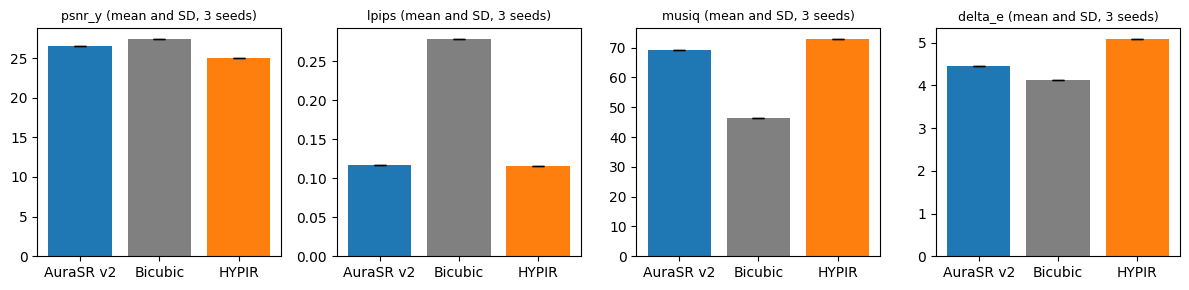

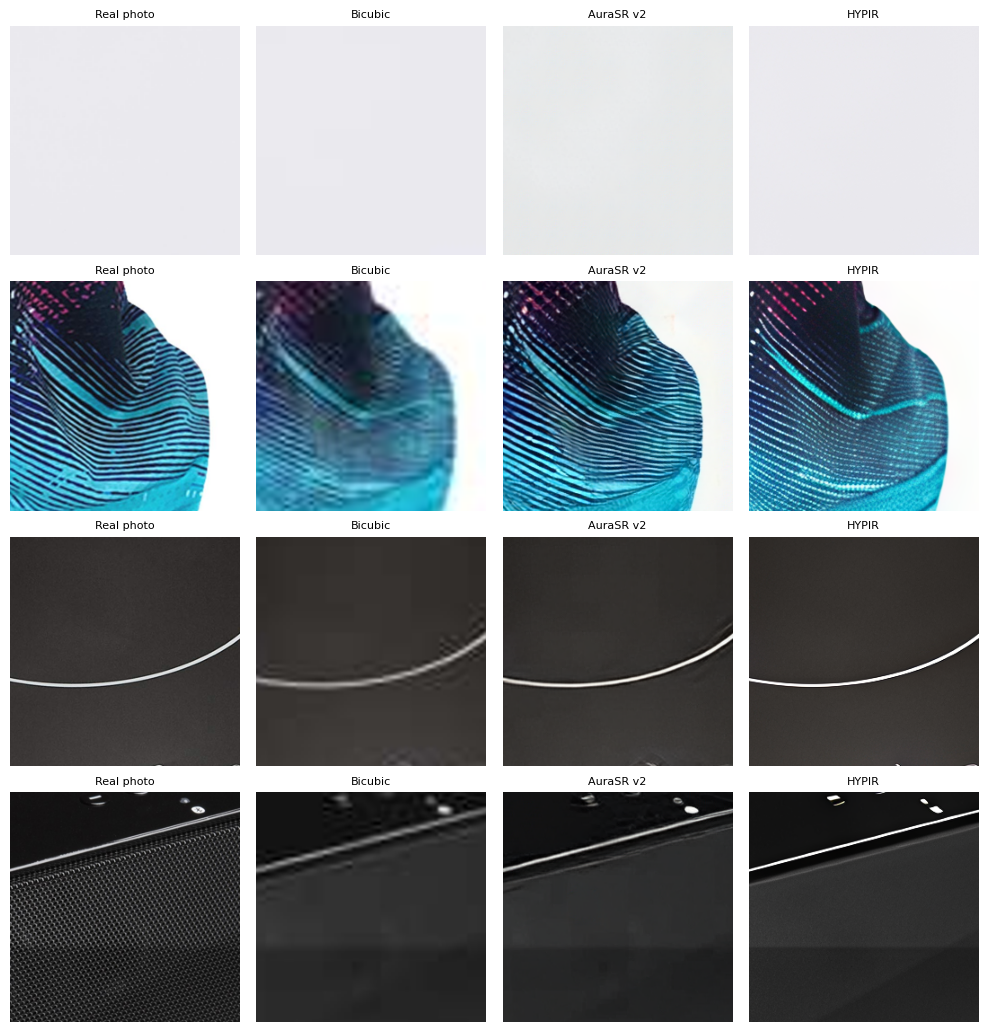

In [ ]:
colours = {A: "tab:blue", B: "tab:orange", BASE: "grey"}
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, metric in zip(axes, ["psnr_y", "lpips", "musiq", "delta_e"]):
    g = by_seed.groupby("system")[metric]
    ax.bar(g.mean().index, g.mean(), yerr=g.std().fillna(0), capsize=4, color=[colours[k] for k in g.mean().index])
    ax.set_title(f"{metric} (mean and SD, 3 seeds)", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "fig_metrics.png", dpi=150)
plt.show()


def crop_box(path, half=128):
    ys, xs = np.where(product_mask(Image.open(path)))
    cx, cy = int(xs.mean()), int(ys.mean())
    return (max(0, cx - half), max(0, cy - half), max(0, cx - half) + 2 * half, max(0, cy - half) + 2 * half)


show = jobs[jobs.damage == "supplier"].head(4)
fig, axes = plt.subplots(len(show), 4, figsize=(10, 2.6 * len(show)))
for i, j in enumerate(show.itertuples()):
    box = crop_box(j.hr)
    for k, (title, path) in enumerate([("Real photo", j.hr), (BASE, OUT / "bicubic" / "seed0" / f"{j.job}.png"),
                                       (A, OUT / "aurasr" / "seed0" / f"{j.job}.png"), (B, OUT / "hypir" / "seed0" / f"{j.job}.png")]):
        axes[i][k].imshow(Image.open(path).crop(box))
        axes[i][k].set_title(title, fontsize=8)
        axes[i][k].axis("off")
fig.tight_layout()
fig.savefig(OUT / "fig_crops.jpg", dpi=120)
plt.show()

## My ratings
The unit allows my own evaluation as user feedback. For the 8 supplier-quality inputs (seed 0) a 384 px crop of the
real photo and of both enlargements is saved, the enlargements as X and Y in a random order; the key goes in a
separate file that I only open after rating. Question: would I publish this enlargement on the product page? (1 = no,
5 = yes as it is). I also time how long it takes me to check each one (`seconds_to_check`); that is the checking time in
the cost table.

In [ ]:
(OUT / "rating").mkdir(exist_ok=True)
key = []
for i, j in enumerate(jobs[jobs.damage == "supplier"].itertuples(), 1):
    swap = random.Random(i).random() < 0.5
    x, y = (B, A) if swap else (A, B)
    box = crop_box(j.hr, half=192)
    Image.open(j.hr).crop(box).save(OUT / "rating" / f"item{i:02d}_real.png")
    for label, system in (("X", x), ("Y", y)):
        Image.open(OUT / ("aurasr" if system == A else "hypir") / "seed0" / f"{j.job}.png").crop(box).save(OUT / "rating" / f"item{i:02d}_{label}.png")
    key.append({"item": i, "input": j.job, "X": x, "Y": y})
pd.DataFrame(key).to_csv(OUT / "rating" / "key.csv", index=False)
pd.DataFrame({"item": range(1, len(key) + 1), "score_X": "", "score_Y": "", "seconds_to_check": ""}).to_csv(OUT / "rating" / "my_ratings.csv", index=False)

In [ ]:
# run this after filling in rating/my_ratings.csv
r = pd.read_csv(OUT / "rating" / "my_ratings.csv").merge(pd.read_csv(OUT / "rating" / "key.csv"))
if r.score_X.notna().all():
    scores_r = pd.concat([r[["X", "score_X"]].set_axis(["system", "score"], axis=1), r[["Y", "score_Y"]].set_axis(["system", "score"], axis=1)])
    print(scores_r.groupby("system").score.agg(["mean", lambda s: (s >= 4).mean()]).set_axis(["mean score", "share rated 4 or 5"], axis=1))
    print(f"my checking time: {r.seconds_to_check.mean():.1f} s per photo (rerun the cost cell to use it)")
else:
    print("ratings not filled in yet")

ratings not filled in yet


In [ ]:
pd.Series({"date": time.ctime(), "gpu": torch.cuda.get_device_name(0), "torch": torch.__version__,
           "diffusers": __import__("diffusers").__version__, "pyiqa": __import__("importlib.metadata").metadata.version("pyiqa"),
           "hypir commit": "b61d107c6cef38f01a93c7833558869731cfa8c1", "seeds": SEEDS, "inputs": len(jobs)}).to_json(OUT / "run_info.json")
shutil.make_archive("/kaggle/working/pair3_results", "zip", OUT)

'/kaggle/working/pair3_results.zip'

In [1]:
# my ratings, added after the Kaggle run (my_ratings.csv and key.csv from rating/, speed_cost.csv from the results)
import pandas as pd
from pathlib import Path
from scipy.stats import wilcoxon


def find(name):
    hits = sorted(Path("/content").rglob(name))
    if not hits:
        raise FileNotFoundError(f"{name} not found: upload it with the folder icon on the left and wait for the upload to finish")
    return hits[0]


r = pd.read_csv(find("my_ratings.csv")).merge(pd.read_csv(find("key.csv")))
r = r.dropna(subset=["score_X", "score_Y"])   # item 1 left out: its crop showed only white background, not the product
scores = pd.concat([r[["X", "score_X"]].set_axis(["system", "score"], axis=1),
                    r[["Y", "score_Y"]].set_axis(["system", "score"], axis=1)])
summary = scores.groupby("system").score.agg(["mean", lambda s: (s >= 4).mean()]).set_axis(["mean score", "share rated 4 or 5"], axis=1)
display(summary.round(2))

wide = scores.assign(item=list(r.item) * 2).pivot(index="item", columns="system", values="score")
d = wide["AuraSR v2"] - wide["HYPIR"]
print(len(r), "items rated")
print("items where AuraSR v2 scored higher:", (d > 0).sum(), "| HYPIR higher:", (d < 0).sum(), "| ties:", (d == 0).sum())
print("Wilcoxon p on scores:", round(wilcoxon(d).pvalue, 3) if (d != 0).any() else "all ties")

# cost again, with my measured checking time instead of 60 s
secs = r.seconds_to_check.mean()
cost = pd.read_csv(find("speed_cost.csv"))
cost["check AUD per photo"] = secs / 3600 * 61.41
cost["saving AUD per month (1,500 photos, if all usable)"] = (36.09 - cost["GPU AUD per photo"] - cost["check AUD per photo"]) * 1500
cost["share I would publish"] = cost.system.map(summary["share rated 4 or 5"])
cost["saving AUD per month (only photos I would publish)"] = cost["saving AUD per month (1,500 photos, if all usable)"] * cost["share I would publish"]
print(f"my checking time: {secs:.1f} s per photo")
display(cost.round(3))

summary.to_csv("user_ratings_summary.csv")
cost.to_csv("speed_cost_with_check.csv", index=False)

,mean score,share rated 4 or 5
system,,
AuraSR v2,2.14,0.00
HYPIR,4.43,0.86


7 items rated
items where AuraSR v2 scored higher: 0 | HYPIR higher: 7 | ties: 0
Wilcoxon p on scores: 0.016
my checking time: 7.1 s per photo


,system,seconds per photo,GPU energy Wh per photo (max),GPU AUD per photo,check AUD per photo,reshoot AUD per photo,"saving AUD per month (1,500 photos, if all usable)",share I would publish,saving AUD per month (only photos I would publish)
0,AuraSR v2,4.625,0.090,0.001,0.122,36.09,53950.324,0.000,0.000
1,HYPIR,12.051,0.234,0.003,0.122,36.09,53947.261,0.857,46240.509
